# 03 — LLM benchmark on EKS and A/B comparison

Qwen2.5-1.5B (llama.cpp, CPU) on EKS `platform-apps`. Three sources, all read from committed files:
1. [`bench-llm-eks-t*-20261030.json`](../docs/evidence/aws/): `bench_llm.py`, trying llama.cpp thread counts (3, 4, 6) at concurrency levels 1/2/4;
2. [`llmd-benchmark/`](../docs/evidence/aws/llmd-benchmark/): llm-d-benchmark (inference-perf), three load levels of 0.1/0.2/0.4 requests/second;
3. A/B: Prometheus and the eval results of the two Agents (1.5B and 0.5B).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
EVIDENCE = ROOT / "docs" / "evidence"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

## 1. llama.cpp thread count and concurrency

Each level has only 8 requests, so differences under ~10% count as a tie.

In [2]:
bench = pd.concat(
    [
        pd.read_json(p, lines=True)
        for p in sorted((EVIDENCE / "aws").glob("bench-llm-eks-t*-20261030.json"))
    ]
)
bench["threads"] = bench["label"].str.removeprefix("eks-t")
bench[["threads", "concurrency", "requests", "p50_s", "p95_s", "req_per_s", "output_tok_per_s"]]

,threads,concurrency,requests,p50_s,p95_s,req_per_s,output_tok_per_s
0,3,1,8,5.38,5.62,0.204,10.7
1,3,2,8,7.70,14.97,0.214,11.3
2,3,4,8,10.96,12.44,0.345,17.8
0,4,1,8,4.74,5.19,0.229,12.0
1,4,2,8,7.60,13.93,0.225,11.8
2,4,4,8,12.57,19.14,0.269,14.0
0,6,1,8,5.66,6.25,0.188,9.9
1,6,2,8,8.63,14.70,0.204,10.6
2,6,4,8,11.02,12.60,0.342,17.7


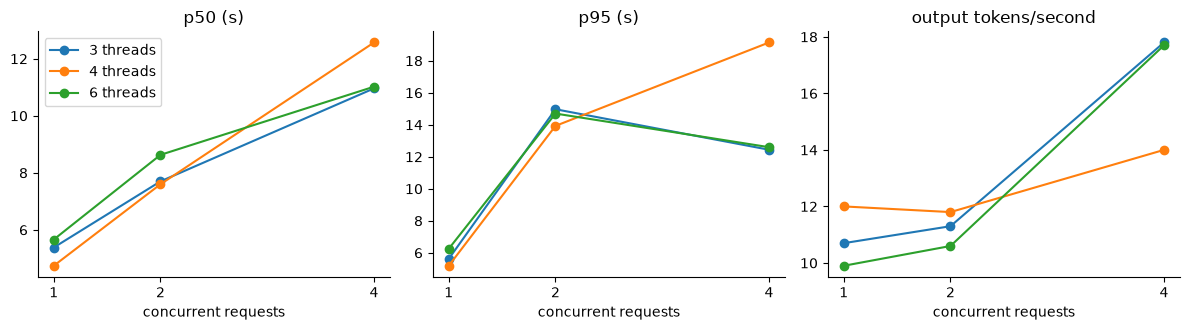

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for (title, col), ax in zip(
    {"p50 (s)": "p50_s", "p95 (s)": "p95_s", "output tokens/second": "output_tok_per_s"}.items(),
    axes,
):
    for threads, g in bench.groupby("threads"):
        ax.plot(g["concurrency"], g[col], marker="o", label=f"{threads} threads")
    ax.set_xticks([1, 2, 4])
    ax.set_xlabel("concurrent requests")
    ax.set_title(title)
axes[0].legend()
plt.tight_layout()
plt.show()

In [4]:
t = bench.pivot(index="concurrency", columns="threads", values="output_tok_per_s")
p50 = bench.pivot(index="concurrency", columns="threads", values="p50_s")
print("output tokens/second by (concurrency, threads):")
print(t.to_string())
print(
    f"\n3 threads: concurrency 1 -> 4 raises throughput {t.loc[4, '3'] / t.loc[1, '3']:.2f}x, p50 rises {p50.loc[4, '3'] / p50.loc[1, '3']:.2f}x"
)

output tokens/second by (concurrency, threads):
threads         3     4     6
concurrency                  
1            10.7  12.0   9.9
2            11.3  11.8  10.6
4            17.8  14.0  17.7

3 threads: concurrency 1 -> 4 raises throughput 1.66x, p50 rises 2.04x


Adding concurrent requests raises token throughput (about 1.7x going from 1 to 4) but **p50 nearly doubles**: the CPU is the bottleneck, and most of the extra time is queueing.
At concurrency 4, the 4-thread configuration is clearly the worst (14.0 tokens/second vs. 17.7–17.8 for 3 and 6 threads); 3 and 6 threads are nearly equal, so 3 threads is chosen because it uses less CPU.
Each cell has only 8 requests, so treat this as a trend only.

## 2. llm-d-benchmark (inference-perf), 3 load levels

In [5]:
import re

rates = [
    float(x)
    for x in re.findall(
        r"rate:\s*([\d.]+)",
        (EVIDENCE / "aws" / "llmd-benchmark" / "llmd-inference-perf-qwen-cpu.yaml").read_text(),
    )
]
rows = []
for i, rate in enumerate(rates):
    d = json.loads(
        (EVIDENCE / "aws" / "llmd-benchmark" / f"stage_{i}_lifecycle_metrics.json").read_text()
    )
    s = d["successes"]
    rows.append(
        {
            "load (req/s)": rate,
            "requests": s["count"],
            "errors": (d["failures"] or {}).get("count", 0),
            "median TTFT (s)": s["latency"]["time_to_first_token"]["median"],
            "p90 TTFT (s)": s["latency"]["time_to_first_token"]["p90"],
            "median latency (s)": s["latency"]["request_latency"]["median"],
            "p90 latency (s)": s["latency"]["request_latency"]["p90"],
            "achieved (req/s)": s["throughput"]["requests_per_sec"],
            "output tok/s": s["throughput"]["output_tokens_per_sec"],
        }
    )
llmd = pd.DataFrame(rows)
llmd.round(3)

,load (req/s),requests,errors,median TTFT (s),p90 TTFT (s),median latency (s),p90 latency (s),achieved (req/s),output tok/s
0,0.1,6,0,1.881,2.864,5.485,6.304,0.092,2.950
1,0.2,12,0,1.955,4.227,7.220,9.970,0.232,7.078
2,0.4,24,0,5.616,14.996,13.643,20.646,0.340,10.237


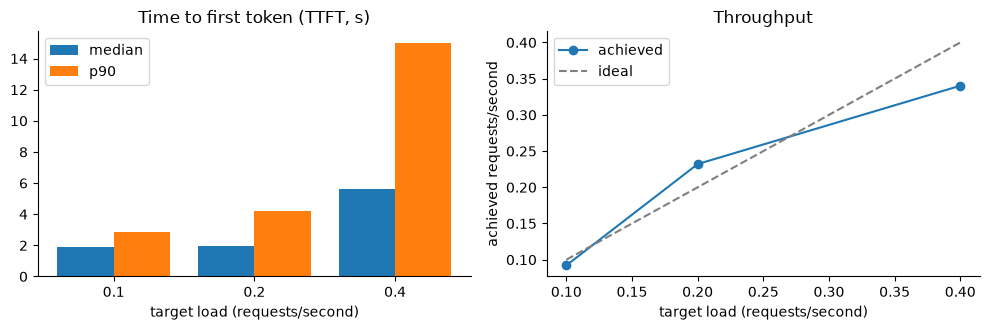

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
x = np.arange(len(llmd))
axes[0].bar(x - 0.2, llmd["median TTFT (s)"], 0.4, label="median")
axes[0].bar(x + 0.2, llmd["p90 TTFT (s)"], 0.4, label="p90")
axes[0].set_xticks(x, llmd["load (req/s)"])
axes[0].set_xlabel("target load (requests/second)")
axes[0].set_title("Time to first token (TTFT, s)")
axes[0].legend()
axes[1].plot(llmd["load (req/s)"], llmd["achieved (req/s)"], marker="o", label="achieved")
axes[1].plot(llmd["load (req/s)"], llmd["load (req/s)"], ls="--", color="gray", label="ideal")
axes[1].set_xlabel("target load (requests/second)")
axes[1].set_ylabel("achieved requests/second")
axes[1].set_title("Throughput")
axes[1].legend()
plt.tight_layout()
plt.show()

In [7]:
assert llmd["errors"].sum() == 0 and llmd["requests"].sum() == 42
print("total", int(llmd["requests"].sum()), "requests,", int(llmd["errors"].sum()), "errors")

total 42 requests, 0 errors


The 0.1 and 0.2 req/s levels are served fine (median TTFT ~1.9 s). At **0.4 req/s the system saturates**: median TTFT rises almost threefold (5.6 s), p90 is close to 15 s,
and the achieved throughput (0.34) is below the target load (0.4). This is one short run (60 s per level, prompts of ~128 tokens), with no confidence interval yet.

## 3. A/B: two models, two Agents

In [8]:
ab = json.loads((EVIDENCE / "aws" / "ab-llm-prometheus-20261031.json").read_text())
print(ab["setup"][:230], "...")
pd.DataFrame({"increase over 1 hour": ab["increase_1h"], "total": ab["total"]})

agentgateway virtual model platform-chat, weighted 1:1 between qwen2.5-1.5b-instruct (A, deploy qwen) and qwen2.5-0.5b-instruct (B, deploy qwen-small) on EKS platform-apps; traffic from scripts/evidence/bench_llm.py --model platfo ...


,increase over 1 hour,total
qwen2.5-1.5b-instruct,54.23,642
qwen2.5-0.5b-instruct,27.58,30


In [9]:
print(ab["note"])

B only exists since today (total 30 = all bench traffic it received); A also serves data-agent, coordinator and sandbox agents, so its count is higher than the bench share alone


In [10]:
evals = pd.concat(
    [
        pd.read_json(p, lines=True)
        for p in sorted((EVIDENCE / "aws").glob("agent-eval-data-agent*-20261031.jsonl"))
    ]
)
graded = evals[(evals["gradable"]) & (evals["agent"].isin(["data-agent", "data-agent-b"]))]
summary = (
    graded.groupby("agent")
    .agg(questions=("pass", "size"), passed=("pass", "sum"), mean_seconds=("seconds", "mean"))
    .round(2)
)
summary["pass rate"] = (summary["passed"] / summary["questions"]).round(3)
summary

,questions,passed,mean_seconds,pass rate
agent,,,,
data-agent,12,12,10.17,1.000
data-agent-b,12,4,6.00,0.333


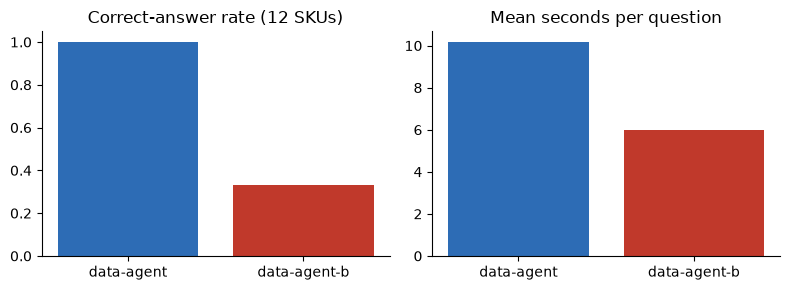

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
axes[0].bar(summary.index, summary["pass rate"], color=["#2d6cb5", "#c0392b"])
axes[0].set_ylim(0, 1.05)
axes[0].set_title("Correct-answer rate (12 SKUs)")
axes[1].bar(summary.index, summary["mean_seconds"], color=["#2d6cb5", "#c0392b"])
axes[1].set_title("Mean seconds per question")
plt.tight_layout()
plt.show()

**A clear trade-off:** the 0.5B model is faster (about 6.0 s vs. 10.2 s per question, i.e. ~40% shorter) but answers correctly far less often than 1.5B on the same 12 SKUs (4/12 vs. 12/12).
The sample is small (12), so use it only to see the trend, not to estimate an exact accuracy rate.